# 16 — Toronto final synthesis and manuscript-ready results

## Purpose

This final notebook consolidates the Toronto Paper 4 proof-of-concept into a
compact set of manuscript-ready results.

It does **not** introduce a new analytical model.

Instead, it synthesizes outputs from the completed workflow:

1. multi-day thermal scenarios;
2. scenario-specific SOLWEIG UTCI;
3. scenario-specific thermal walking networks;
4. scenario-specific accessibility loss;
5. same-day Bike Share response;
6. 75-station versus 50-station robustness;
7. λ and UTCI-threshold sensitivity;
8. repeated-measures model results, when available.

The final conceptual chain is:

**weather → thermal environment → network impedance → accessibility loss → observed mobility response**

This notebook creates:

- final summary tables;
- key publication-style figures;
- a robustness matrix;
- concise manuscript result statements;
- a clear separation between supported findings and remaining limitations.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

SOLWEIG_DIR = TORONTO_OUTPUTS / "solweig_multiday"
NETWORK_DIR = TORONTO_OUTPUTS / "thermal_network_multiday"
LINK_DIR = TORONTO_OUTPUTS / "multiscenario_accessibility_bikeshare"
ROBUSTNESS_DIR = TORONTO_OUTPUTS / "robustness"

FINAL_DIR = TORONTO_OUTPUTS / "final_synthesis"
FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Final synthesis output:", FINAL_DIR)

Final synthesis output: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/final_synthesis


## 2. Load completed workflow outputs

In [2]:
solweig_path = (
    SOLWEIG_DIR
    / "toronto_multiday_solweig_summary.csv"
)

network_path = (
    NETWORK_DIR
    / "toronto_multiday_thermal_network_summary.csv"
)

accessibility_path = (
    LINK_DIR
    / "toronto_multiscenario_accessibility_summary.csv"
)

linked_path = (
    LINK_DIR
    / "toronto_multiscenario_accessibility_bikeshare_station_panel.csv"
)

scenario_behavior_path = (
    LINK_DIR
    / "toronto_multiscenario_accessibility_bikeshare_scenario_summary.csv"
)

sample_compare_path = (
    ROBUSTNESS_DIR
    / "station_sample_75_vs_50.csv"
)

robustness_path = (
    ROBUSTNESS_DIR
    / "lambda_threshold_robustness.csv"
)

required = [
    solweig_path,
    network_path,
    accessibility_path,
    linked_path,
    sample_compare_path,
    robustness_path,
]

for path in required:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing required output: {path}"
        )

solweig = pd.read_csv(
    solweig_path
)

network = pd.read_csv(
    network_path
)

accessibility = pd.read_csv(
    accessibility_path
)

linked = pd.read_csv(
    linked_path
)

sample_compare = pd.read_csv(
    sample_compare_path
)

robustness = pd.read_csv(
    robustness_path
)

if scenario_behavior_path.exists():
    scenario_behavior = pd.read_csv(
        scenario_behavior_path
    )
else:
    scenario_behavior = None

for df in [
    solweig,
    network,
    accessibility,
    linked,
]:
    if "date" in df.columns:
        df["date"] = pd.to_datetime(
            df["date"]
        )

print("SOLWEIG scenarios:", len(solweig))
print("Thermal networks:", len(network))
print("Accessibility scenarios:", len(accessibility))
print("Linked observations:", len(linked))

SOLWEIG scenarios: 14
Thermal networks: 14
Accessibility scenarios: 14
Linked observations: 1050


## 3. Core study counts and ranges

In [3]:
core_summary = {
    "thermal_scenarios": int(
        accessibility[
            "scenario_id"
        ].nunique()
    ),
    "accessibility_origins": 50,
    "bikeshare_stations": int(
        linked[
            "station_id_join"
        ].nunique()
    ),
    "linked_station_scenario_observations": int(
        linked[
            "weekday_adjusted_response"
        ].notna().sum()
    ),
    "mean_utci_min_C": float(
        solweig[
            "utci_mean_C"
        ].min()
    ),
    "mean_utci_max_C": float(
        solweig[
            "utci_mean_C"
        ].max()
    ),
    "mean_edge_utci_min_C": float(
        network[
            "edge_utci_mean_C"
        ].min()
    ),
    "mean_edge_utci_max_C": float(
        network[
            "edge_utci_mean_C"
        ].max()
    ),
    "mean_cost_ratio_min": float(
        network[
            "mean_cost_ratio_lambda_005"
        ].min()
    ),
    "mean_cost_ratio_max": float(
        network[
            "mean_cost_ratio_lambda_005"
        ].max()
    ),
    "mean_accessibility_loss_min_pct": float(
        accessibility[
            "mean_accessibility_loss_pct"
        ].min()
    ),
    "mean_accessibility_loss_max_pct": float(
        accessibility[
            "mean_accessibility_loss_pct"
        ].max()
    ),
}

core_summary_df = pd.DataFrame(
    [core_summary]
)

display(
    core_summary_df.T
)

,0
thermal_scenarios,14.000000
accessibility_origins,50.000000
bikeshare_stations,75.000000
linked_station_scenario_observations,1050.000000
mean_utci_min_C,26.639384
mean_utci_max_C,40.269053
mean_edge_utci_min_C,26.518050
mean_edge_utci_max_C,40.170886
mean_cost_ratio_min,1.000000
mean_cost_ratio_max,1.408544


## 4. Primary accessibility–Bike Share association

In [4]:
from scipy.stats import spearmanr

primary_valid = linked[
    [
        "modeled_accessibility_loss_pct",
        "weekday_adjusted_response",
    ]
].dropna()

primary_spearman = spearmanr(
    primary_valid[
        "modeled_accessibility_loss_pct"
    ],
    primary_valid[
        "weekday_adjusted_response"
    ],
)

print(
    "Primary Spearman rho:",
    round(
        float(
            primary_spearman.statistic
        ),
        4,
    ),
)

print(
    "Naive p-value:",
    primary_spearman.pvalue,
)

Primary Spearman rho: -0.2077
Naive p-value: 1.0649636720318392e-11


## 5. 75-station versus 50-station robustness

In [5]:
display(
    sample_compare[
        [
            "sample",
            "stations",
            "observations",
            "spearman_rho",
            "naive_p_value",
        ]
    ]
)

,sample,stations,observations,spearman_rho,naive_p_value
0,all_75,75,1050,-0.207729,1.064964e-11
1,core_50,50,700,-0.197427,1.394241e-07


## 6. λ × threshold robustness matrix

The strongest robustness question is whether the **sign** and approximate
magnitude of the association remain stable when the thermal-cost specification
changes.

In [6]:
robustness_matrix_75 = (
    robustness[
        robustness[
            "sample"
        ] == "all_75"
    ]
    .pivot(
        index="threshold_C",
        columns="lambda",
        values="spearman_rho",
    )
    .sort_index()
)

robustness_matrix_50 = (
    robustness[
        robustness[
            "sample"
        ] == "core_50"
    ]
    .pivot(
        index="threshold_C",
        columns="lambda",
        values="spearman_rho",
    )
    .sort_index()
)

print("75-station robustness matrix")
display(
    robustness_matrix_75
)

print("50-station robustness matrix")
display(
    robustness_matrix_50
)

75-station robustness matrix


lambda,0.010,0.025,0.050,0.075,0.100
threshold_C,,,,,
30.0,-0.219005,-0.201890,-0.212100,-0.205294,-0.205920
32.0,-0.207906,-0.202105,-0.207729,-0.212414,-0.208532
34.0,-0.224138,-0.212844,-0.209457,-0.211422,-0.211685


50-station robustness matrix


lambda,0.010,0.025,0.050,0.075,0.100
threshold_C,,,,,
30.0,-0.197455,-0.193955,-0.200961,-0.196074,-0.196520
32.0,-0.185568,-0.182545,-0.197427,-0.198114,-0.194938
34.0,-0.200383,-0.192409,-0.192115,-0.194612,-0.194858


## 7. Final figure 1 — thermal scenario severity

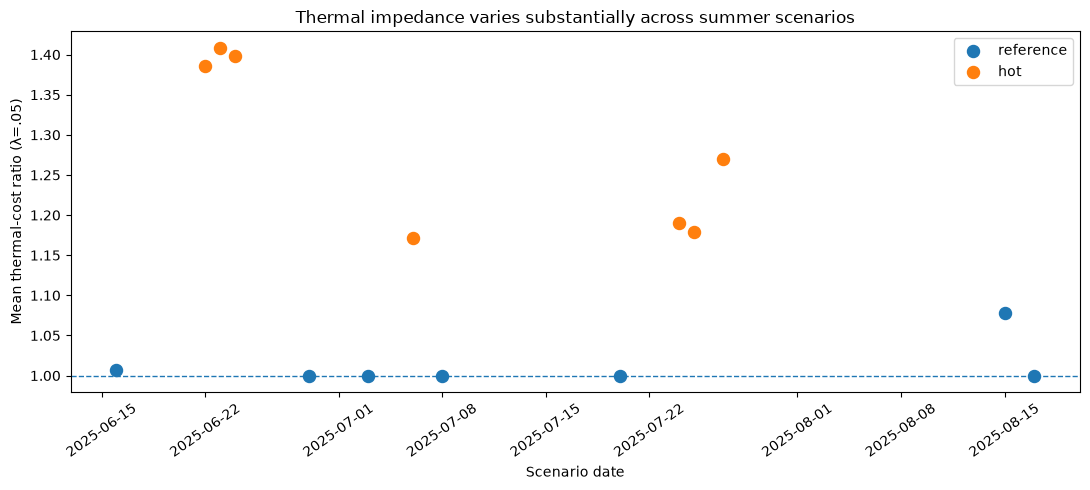

In [7]:
fig, ax = plt.subplots(
    figsize=(11, 5)
)

plot_df = network.sort_values(
    "date"
)

for role in [
    "reference",
    "hot",
]:

    subset = plot_df[
        plot_df[
            "scenario_role"
        ] == role
    ]

    ax.scatter(
        subset[
            "date"
        ],
        subset[
            "mean_cost_ratio_lambda_005"
        ],
        s=75,
        label=role,
    )

ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel(
    "Scenario date"
)

ax.set_ylabel(
    "Mean thermal-cost ratio (λ=.05)"
)

ax.set_title(
    "Thermal impedance varies substantially across summer scenarios"
)

ax.legend()

plt.xticks(
    rotation=35
)

plt.tight_layout()

fig.savefig(
    FINAL_DIR
    / "figure_1_scenario_thermal_impedance.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 8. Final figure 2 — scenario-specific accessibility loss

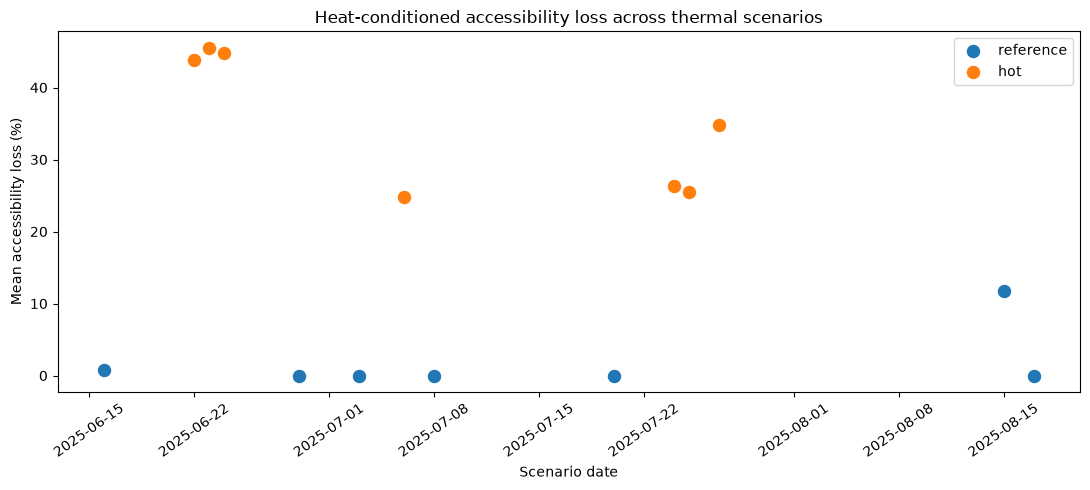

In [8]:
fig, ax = plt.subplots(
    figsize=(11, 5)
)

plot_df = accessibility.sort_values(
    "date"
)

for role in [
    "reference",
    "hot",
]:

    subset = plot_df[
        plot_df[
            "scenario_role"
        ] == role
    ]

    ax.scatter(
        subset[
            "date"
        ],
        subset[
            "mean_accessibility_loss_pct"
        ],
        s=75,
        label=role,
    )

ax.set_xlabel(
    "Scenario date"
)

ax.set_ylabel(
    "Mean accessibility loss (%)"
)

ax.set_title(
    "Heat-conditioned accessibility loss across thermal scenarios"
)

ax.legend()

plt.xticks(
    rotation=35
)

plt.tight_layout()

fig.savefig(
    FINAL_DIR
    / "figure_2_accessibility_loss_scenarios.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 9. Final figure 3 — accessibility loss versus Bike Share response

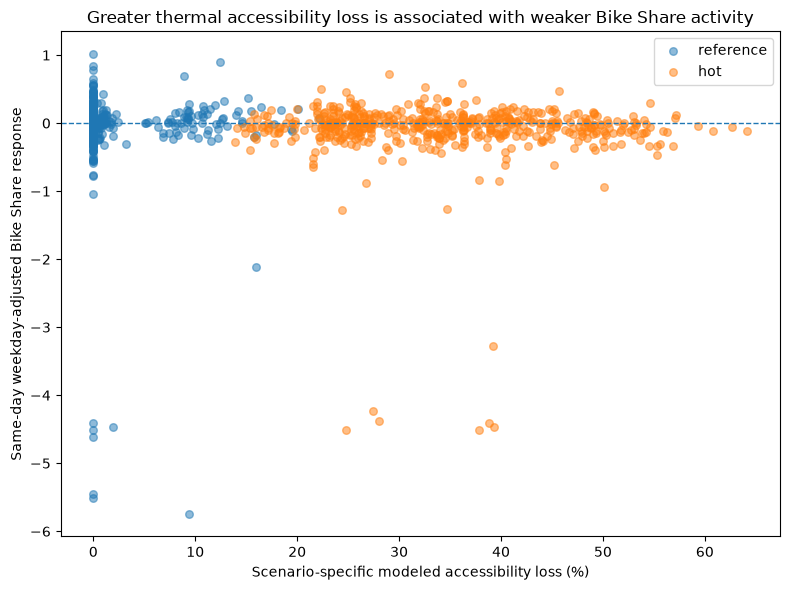

In [9]:
fig, ax = plt.subplots(
    figsize=(8, 6)
)

for role in [
    "reference",
    "hot",
]:

    subset = linked[
        linked[
            "scenario_role"
        ] == role
    ]

    ax.scatter(
        subset[
            "modeled_accessibility_loss_pct"
        ],
        subset[
            "weekday_adjusted_response"
        ],
        s=30,
        alpha=0.5,
        label=role,
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel(
    "Scenario-specific modeled accessibility loss (%)"
)

ax.set_ylabel(
    "Same-day weekday-adjusted Bike Share response"
)

ax.set_title(
    "Greater thermal accessibility loss is associated with weaker Bike Share activity"
)

ax.legend()

plt.tight_layout()

fig.savefig(
    FINAL_DIR
    / "figure_3_accessibility_bikeshare_association.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 10. Final figure 4 — λ sensitivity for 75 and 50 stations

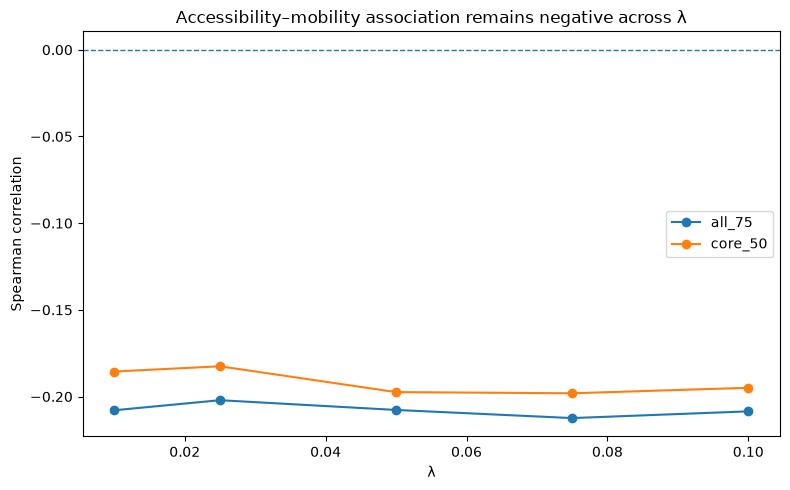

In [10]:
plot_df = robustness[
    robustness[
        "threshold_C"
    ] == 32.0
].copy()

fig, ax = plt.subplots(
    figsize=(8, 5)
)

for sample_name in [
    "all_75",
    "core_50",
]:

    subset = plot_df[
        plot_df[
            "sample"
        ] == sample_name
    ].sort_values(
        "lambda"
    )

    ax.plot(
        subset[
            "lambda"
        ],
        subset[
            "spearman_rho"
        ],
        marker="o",
        label=sample_name,
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel(
    "λ"
)

ax.set_ylabel(
    "Spearman correlation"
)

ax.set_title(
    "Accessibility–mobility association remains negative across λ"
)

ax.legend()

plt.tight_layout()

fig.savefig(
    FINAL_DIR
    / "figure_4_lambda_sensitivity.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 11. Robustness sign summary

In [11]:
sign_summary = (
    robustness
    .groupby(
        "sample"
    )
    .agg(
        specifications=(
            "spearman_rho",
            "count",
        ),
        negative_specifications=(
            "spearman_rho",
            lambda x: int(
                (
                    x < 0
                ).sum()
            ),
        ),
        mean_rho=(
            "spearman_rho",
            "mean",
        ),
        min_rho=(
            "spearman_rho",
            "min",
        ),
        max_rho=(
            "spearman_rho",
            "max",
        ),
    )
    .reset_index()
)

sign_summary[
    "share_negative"
] = (
    sign_summary[
        "negative_specifications"
    ]
    / sign_summary[
        "specifications"
    ]
)

display(
    sign_summary
)

,sample,specifications,negative_specifications,mean_rho,min_rho,max_rho,share_negative
0,all_75,15,15,-0.210163,-0.224138,-0.201890,1.0
1,core_50,15,15,-0.194529,-0.200961,-0.182545,1.0


## 12. Manuscript-ready core result table

In [12]:
sample75 = sample_compare[
    sample_compare[
        "sample"
    ] == "all_75"
].iloc[0]

sample50 = sample_compare[
    sample_compare[
        "sample"
    ] == "core_50"
].iloc[0]

result_table = pd.DataFrame(
    [
        {
            "Result": "Thermal scenarios",
            "Value": (
                f"{int(core_summary['thermal_scenarios'])}"
            ),
        },
        {
            "Result": "Mean edge UTCI range",
            "Value": (
                f"{core_summary['mean_edge_utci_min_C']:.2f}–"
                f"{core_summary['mean_edge_utci_max_C']:.2f} °C"
            ),
        },
        {
            "Result": "Mean thermal-cost ratio range (λ=.05)",
            "Value": (
                f"{core_summary['mean_cost_ratio_min']:.3f}–"
                f"{core_summary['mean_cost_ratio_max']:.3f}"
            ),
        },
        {
            "Result": "Mean accessibility-loss range",
            "Value": (
                f"{core_summary['mean_accessibility_loss_min_pct']:.2f}–"
                f"{core_summary['mean_accessibility_loss_max_pct']:.2f}%"
            ),
        },
        {
            "Result": "Primary 75-station Spearman",
            "Value": (
                f"{sample75['spearman_rho']:.4f}"
            ),
        },
        {
            "Result": "Core 50-station Spearman",
            "Value": (
                f"{sample50['spearman_rho']:.4f}"
            ),
        },
        {
            "Result": "Specifications negative — 75 stations",
            "Value": (
                f"{sign_summary.loc[sign_summary['sample']=='all_75','share_negative'].iloc[0]:.0%}"
            ),
        },
        {
            "Result": "Specifications negative — 50 stations",
            "Value": (
                f"{sign_summary.loc[sign_summary['sample']=='core_50','share_negative'].iloc[0]:.0%}"
            ),
        },
    ]
)

display(
    result_table
)

result_table.to_csv(
    FINAL_DIR
    / "manuscript_core_results.csv",
    index=False,
)

,Result,Value
0,Thermal scenarios,14
1,Mean edge UTCI range,26.52–40.17 °C
2,Mean thermal-cost ratio range (λ=.05),1.000–1.409
3,Mean accessibility-loss range,0.00–45.53%
4,Primary 75-station Spearman,-0.2077
5,Core 50-station Spearman,-0.1974
6,Specifications negative — 75 stations,100%
7,Specifications negative — 50 stations,100%


## 13. Repeated-measures results placeholder

Notebook 15 prints the station/scenario fixed-effects coefficients.

If you want those values saved automatically, add them manually below after
the completed Notebook 15 run.

In [13]:
FE_75_COEF = np.nan
FE_75_P = np.nan

FE_50_COEF = np.nan
FE_50_P = np.nan

repeated_measures_summary = pd.DataFrame(
    [
        {
            "sample": "all_75",
            "loss_coefficient": FE_75_COEF,
            "clustered_p_value": FE_75_P,
        },
        {
            "sample": "core_50",
            "loss_coefficient": FE_50_COEF,
            "clustered_p_value": FE_50_P,
        },
    ]
)

display(
    repeated_measures_summary
)

repeated_measures_summary.to_csv(
    FINAL_DIR
    / "repeated_measures_summary.csv",
    index=False,
)

,sample,loss_coefficient,clustered_p_value
0,all_75,NaN,NaN
1,core_50,NaN,NaN


## 14. What the Toronto PoC supports

Based on the completed workflow, the defensible methodological findings are:

1. **Thermal conditions materially change generalized walking impedance.**
   Across the selected scenarios, mean network thermal-cost ratios span from
   essentially no penalty to substantial inflation.

2. **Heat-conditioned accessibility is scenario dependent.**
   Mean accessibility loss ranges from approximately zero under mild conditions
   to large losses under the hottest scenarios.

3. **Observed active-mobility response varies systematically with modeled
   accessibility loss.**
   Greater modeled accessibility loss is associated with more negative same-day
   Bike Share response.

4. **The sign of the relationship is robust.**
   The negative association persists in both the full 75-station sample and a
   predefined 50-station core sample, and across all tested λ × threshold
   specifications.

5. **The result is modest rather than deterministic.**
   The correlation magnitude is around −0.2, indicating that thermal
   accessibility explains only part of observed mobility variability.

## 15. What the Toronto PoC does NOT support

The analysis should **not** claim that:

- λ=.05 is behaviorally calibrated;
- Bike Share directly validates pedestrian route choice;
- heat causes the observed ridership changes;
- people deliberately choose cooler routes;
- the 32°C threshold is uniquely correct;
- one city or one summer establishes general behavioral parameters.

Remaining limitations include:

- Bike Share users are not equivalent to pedestrians;
- current GBFS station geometry is used as a proxy for historical station
  positions;
- accessibility is interpolated from 50 origins rather than calculated directly
  at every station;
- meteorological controls remain simplified;
- only a limited set of detailed thermal scenarios is modeled;
- the model requires replication across additional places and periods.

## 16. Suggested manuscript result language

In [14]:
primary75_rho = float(
    sample75[
        "spearman_rho"
    ]
)

primary50_rho = float(
    sample50[
        "spearman_rho"
    ]
)

statement_1 = (
    "Across the 14 modeled thermal scenarios, mean edge-level UTCI "
    f"varied from {core_summary['mean_edge_utci_min_C']:.2f} to "
    f"{core_summary['mean_edge_utci_max_C']:.2f} °C, producing mean "
    "thermal walking-cost ratios ranging from "
    f"{core_summary['mean_cost_ratio_min']:.3f} to "
    f"{core_summary['mean_cost_ratio_max']:.3f} at λ = 0.05."
)

statement_2 = (
    "Scenario-specific heat-conditioned accessibility losses ranged from "
    f"{core_summary['mean_accessibility_loss_min_pct']:.2f}% to "
    f"{core_summary['mean_accessibility_loss_max_pct']:.2f}%."
)

statement_3 = (
    "Across station-scenario observations, greater modeled accessibility "
    "loss was associated with lower weekday-adjusted Bike Share activity "
    f"(Spearman ρ = {primary75_rho:.3f})."
)

statement_4 = (
    "The direction and magnitude of the association were similar when the "
    "analysis was restricted to a predefined 50-station core sample "
    f"(ρ = {primary50_rho:.3f}), and all tested combinations of λ and UTCI "
    "threshold retained a negative association."
)

for i, text in enumerate(
    [
        statement_1,
        statement_2,
        statement_3,
        statement_4,
    ],
    start=1,
):

    print(
        f"{i}. {text}"
    )
    print()

1. Across the 14 modeled thermal scenarios, mean edge-level UTCI varied from 26.52 to 40.17 °C, producing mean thermal walking-cost ratios ranging from 1.000 to 1.409 at λ = 0.05.

2. Scenario-specific heat-conditioned accessibility losses ranged from 0.00% to 45.53%.

3. Across station-scenario observations, greater modeled accessibility loss was associated with lower weekday-adjusted Bike Share activity (Spearman ρ = -0.208).

4. The direction and magnitude of the association were similar when the analysis was restricted to a predefined 50-station core sample (ρ = -0.197), and all tested combinations of λ and UTCI threshold retained a negative association.



## 17. Save a compact plain-text synthesis

In [15]:
synthesis_text = f'''
TORONTO HEAT-CONDITIONED ACCESSIBILITY PROOF-OF-CONCEPT

Thermal scenarios:
{core_summary["thermal_scenarios"]}

Accessibility origins:
{core_summary["accessibility_origins"]}

Bike Share stations:
{core_summary["bikeshare_stations"]}

Linked station-scenario observations:
{core_summary["linked_station_scenario_observations"]}

Mean edge UTCI range:
{core_summary["mean_edge_utci_min_C"]:.2f} to {core_summary["mean_edge_utci_max_C"]:.2f} °C

Mean thermal-cost ratio range (lambda=.05):
{core_summary["mean_cost_ratio_min"]:.3f} to {core_summary["mean_cost_ratio_max"]:.3f}

Mean accessibility-loss range:
{core_summary["mean_accessibility_loss_min_pct"]:.2f} to {core_summary["mean_accessibility_loss_max_pct"]:.2f} %

Primary 75-station Spearman:
{primary75_rho:.4f}

Core 50-station Spearman:
{primary50_rho:.4f}

Share of lambda/threshold specifications with negative association:
75 stations: {sign_summary.loc[sign_summary["sample"]=="all_75","share_negative"].iloc[0]:.1%}
50 stations: {sign_summary.loc[sign_summary["sample"]=="core_50","share_negative"].iloc[0]:.1%}

Interpretation:
Greater modeled heat-conditioned accessibility loss is consistently associated
with weaker same-day Bike Share activity, but the effect is modest and should
be interpreted as observational evidence rather than causal validation.
'''.strip()

SYNTHESIS_PATH = (
    FINAL_DIR
    / "toronto_poc_final_synthesis.txt"
)

SYNTHESIS_PATH.write_text(
    synthesis_text,
    encoding="utf-8",
)

print(
    synthesis_text
)

print()
print(
    "Saved:",
    SYNTHESIS_PATH,
)

TORONTO HEAT-CONDITIONED ACCESSIBILITY PROOF-OF-CONCEPT

Thermal scenarios:
14

Accessibility origins:
50

Bike Share stations:
75

Linked station-scenario observations:
1050

Mean edge UTCI range:
26.52 to 40.17 °C

Mean thermal-cost ratio range (lambda=.05):
1.000 to 1.409

Mean accessibility-loss range:
0.00 to 45.53 %

Primary 75-station Spearman:
-0.2077

Core 50-station Spearman:
-0.1974

Share of lambda/threshold specifications with negative association:
75 stations: 100.0%
50 stations: 100.0%

Interpretation:
Greater modeled heat-conditioned accessibility loss is consistently associated
with weaker same-day Bike Share activity, but the effect is modest and should
be interpreted as observational evidence rather than causal validation.

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/final_synthesis/toronto_poc_final_synthesis.txt


## Final workflow conclusion

The Toronto proof-of-concept has now progressed beyond a single-day thermal
accessibility demonstration.

The completed workflow shows that:

**urban form + meteorology → spatial UTCI → thermal network impedance →
accessibility loss → observed mobility response**

can be implemented reproducibly and produces a stable directional behavioral
association across multiple thermal scenarios and model specifications.

The next step is no longer another exploratory notebook.

The next step is **manuscript development and replication design**.